<a href="https://colab.research.google.com/github/Shreenisha-S30/mini-projects-on-ML/blob/main/Day2_assignment_ML.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**01. Import libraries**


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, precision_score, recall_score
from sklearn.ensemble import RandomForestClassifier

**02. Load the dataset**


In [ ]:
df = pd.read_csv("/content/loan_data.csv")
df.head()

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


**03. Explore the dataset**


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 981 entries, 0 to 980
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Loan_ID            981 non-null    object 
 1   Gender             957 non-null    object 
 2   Married            978 non-null    object 
 3   Dependents         956 non-null    object 
 4   Education          981 non-null    object 
 5   Self_Employed      926 non-null    object 
 6   ApplicantIncome    981 non-null    int64  
 7   CoapplicantIncome  981 non-null    float64
 8   LoanAmount         954 non-null    float64
 9   Loan_Amount_Term   961 non-null    float64
 10  Credit_History     902 non-null    float64
 11  Property_Area      981 non-null    object 
 12  Loan_Status        614 non-null    object 
dtypes: float64(4), int64(1), object(8)
memory usage: 99.8+ KB


In [ ]:
print(df.isnull().sum())

Loan_ID                0
Gender                24
Married                3
Dependents            25
Education              0
Self_Employed         55
ApplicantIncome        0
CoapplicantIncome      0
LoanAmount            27
Loan_Amount_Term      20
Credit_History        79
Property_Area          0
Loan_Status          367
dtype: int64


**04. Handle missing values**


In [ ]:
df.dropna(inplace= True)
df.isnull().sum()

,0
Loan_ID,0
Gender,0
Married,0
Dependents,0
Education,0
Self_Employed,0
ApplicantIncome,0
CoapplicantIncome,0
LoanAmount,0
Loan_Amount_Term,0


**05. Remove duplicates**


In [ ]:
df.duplicated().sum()

np.int64(0)

**06. Detect outliers**


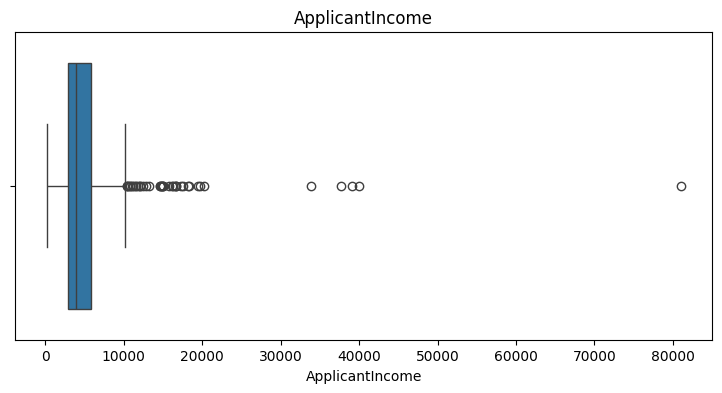

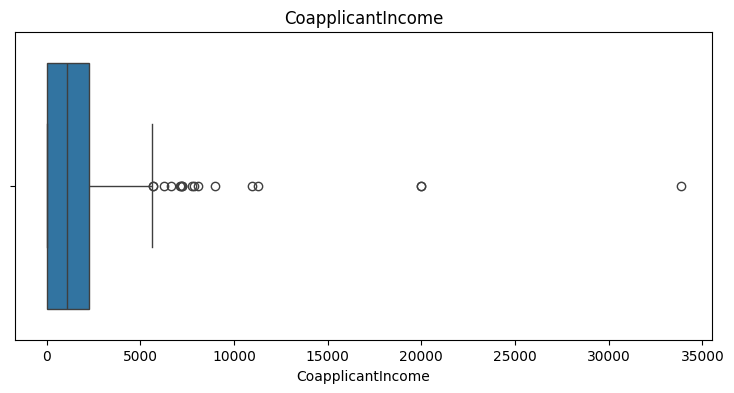

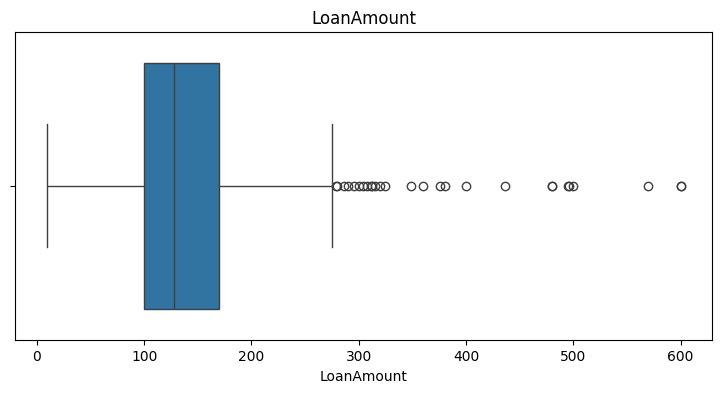

In [ ]:
for col in ["ApplicantIncome", "CoapplicantIncome", "LoanAmount"]:
  plt.figure(figsize=(9, 4))
  sns.boxplot(x=df[col])
  plt.title(col)
  plt.show()

**07. Drop columns and encode categories**


In [ ]:
df = df.drop(columns=['Loan_ID'])

In [ ]:
GE = LabelEncoder()
df["Gender_encoder"] = GE.fit_transform(df["Gender"])
ME = LabelEncoder()
df["married_encoder"] = ME.fit_transform(df["Married"])
DE = LabelEncoder()
df["dependent_encoder"] = DE.fit_transform(df["Dependents"])
EE = LabelEncoder()
df["education_encoder"] = EE.fit_transform(df["Education"])
ESE = LabelEncoder()
df["self_empoyed_encoder"] = ESE.fit_transform(df["Self_Employed"])
PE = LabelEncoder()
df["property_area_encoder"] = PE.fit_transform(df["Property_Area"])
LSE = LabelEncoder()
df["loan_status_encoder"] = LSE.fit_transform(df["Loan_Status"])
df.head()

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status,Gender_encoder,married_encoder,dependent_encoder,education_encoder,self_empoyed_encoder,property_area_encoder,loan_status_encoder
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y,1,0,0,0,0,2,1
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N,1,1,1,0,0,0,0
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y,1,1,0,0,1,2,1
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y,1,1,0,1,0,2,1
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y,1,0,0,0,0,2,1


In [ ]:
df['Loan_Status'].map({'Y': 1, 'N': 0})

,Loan_Status
1,0
2,1
3,1
4,1
5,1
...,...
609,1
610,1
611,1
612,1


**08. Separate features and target**


In [ ]:
X = df[['ApplicantIncome','CoapplicantIncome','LoanAmount','Loan_Amount_Term','Credit_History','Gender_encoder','married_encoder','dependent_encoder','education_encoder','self_empoyed_encoder','property_area_encoder']]
Y = df['Loan_Status']
print(X.shape, Y.shape)

(480, 11) (480,)


**09. Split the dataset**


In [ ]:
x_train,x_test,y_train,y_test = train_test_split(
    X,Y,test_size= 0.20, random_state=42, stratify=Y
)
print("Records for training:", len(x_train))
print("Records for testing:", len(x_test))

Records for training: 384
Records for testing: 96


**10. Apply feature scaling**


In [ ]:
num_cols = ["ApplicantIncome", "CoapplicantIncome",'LoanAmount','Loan_Amount_Term']
my_scaler = StandardScaler()
x_train[num_cols] = my_scaler.fit_transform(x_train[num_cols])
x_test[num_cols] = my_scaler.transform(x_test[num_cols])
print(x_train)

     ApplicantIncome  CoapplicantIncome  LoanAmount  Loan_Amount_Term  \
475         1.875918          -0.192722    0.062059          0.268268   
456        -0.203807          -0.561999   -0.354426          0.268268   
342        -0.160762          -0.114424    0.166181          0.268268   
440        -0.312863           1.282200    0.543620          0.268268   
250        -0.651771           0.854655    0.725833          0.268268   
..               ...                ...         ...               ...   
559        -0.224393           0.277796    0.478544          0.268268   
578        -0.632375           0.250847   -0.497593          0.268268   
205        -0.185602          -0.561999   -0.328396          0.268268   
610        -0.236983          -0.561999   -1.369609         -2.476360   
28         -0.690221          -0.561999   -1.434684          0.268268   

     Credit_History  Gender_encoder  married_encoder  dependent_encoder  \
475             1.0               1             

**11. Train Logistic Regression**


In [ ]:
logr = LogisticRegression()
logr.fit(x_train, y_train)

LogisticRegression()

In [ ]:
logr_predict = logr.predict(x_test)
result = pd.DataFrame(
    {
        "Actual" : y_test,
        "Prediction_by_model" : logr_predict
    }
)
result.head()

,Actual,Prediction_by_model
244,Y,Y
580,Y,Y
603,Y,Y
58,Y,Y
538,N,Y


**12. Evaluate Logistic Regression**



In [ ]:
ac_logr = accuracy_score(y_test,y_predict)
prec_logr = precision_score(y_test, y_predict, pos_label="Y")
rec_logr = recall_score(y_test,y_predict,pos_label="Y")
f1_logr = f1_score(y_test,y_predict,pos_label="Y")
print("Accuracy:", ac_logr)
print("Precision:",prec_logr)
print("Recall:",rec_logr )
print("F1 score:", f1_logr)
print("Confusion Matrix:\n", confusion_matrix(y_test,y_predict))

Accuracy: 0.7708333333333334
Precision: 0.84375
Recall: 0.8181818181818182
F1 score: 0.8307692307692308
Confusion Matrix:
 [[20 10]
 [12 54]]


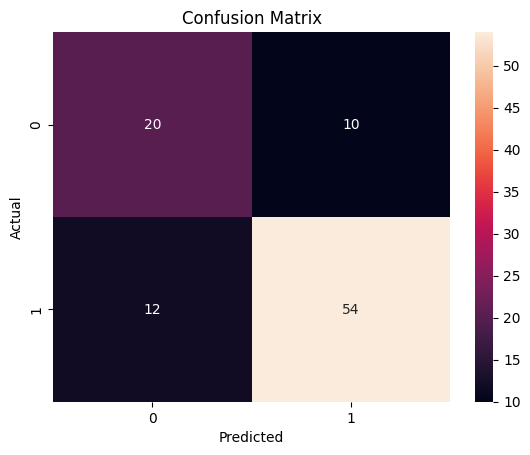

In [ ]:
import matplotlib.pyplot as plt
cm = confusion_matrix(y_test, y_predict)
sns.heatmap(cm, annot=True)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

**13. Train Decision Tree**



In [ ]:
dt = DecisionTreeClassifier()
dt.fit(x_train,y_train)

DecisionTreeClassifier()

In [ ]:
dt_predict = dt.predict(x_test)
result = pd.DataFrame(
    {
        "Actual" : y_test,
        "Prediction_by_model" : dt_predict
    }
)
result.head()

,Actual,Prediction_by_model
244,Y,Y
580,Y,Y
603,Y,Y
58,Y,Y
538,N,Y


**14. Evaluate Decision Tree**



In [ ]:
ac_dt = accuracy_score(y_test,y_predict)
prec_dt = precision_score(y_test, y_predict, pos_label="Y")
rec_dt = recall_score(y_test,y_predict,pos_label="Y")
f1_dt = f1_score(y_test,y_predict,pos_label="Y")
print("Accuracy:", ac_dt)
print("Precision:",prec_dt)
print("Recall:",rec_dt )
print("F1 score:", f1_dt)
print("Confusion Matrix:\n", confusion_matrix(y_test,y_predict))

Accuracy: 0.7708333333333334
Precision: 0.84375
Recall: 0.8181818181818182
F1 score: 0.8307692307692308
Confusion Matrix:
 [[20 10]
 [12 54]]


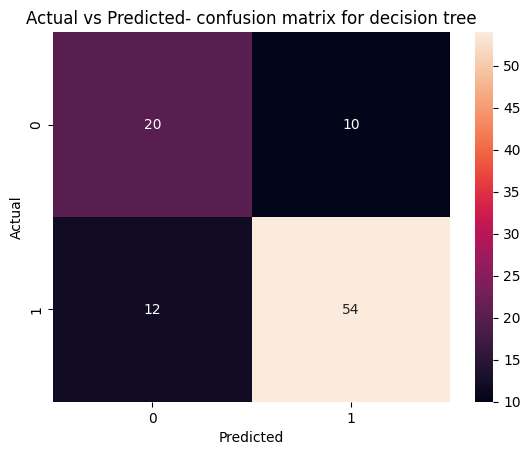

In [ ]:
import matplotlib.pyplot as plt
cm = confusion_matrix(y_test, y_predict)
sns.heatmap(cm, annot=True)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Actual vs Predicted- confusion matrix for decision tree")
plt.show()

15. Visualize and download the Decision Tree



In [ ]:
from sklearn.tree import plot_tree

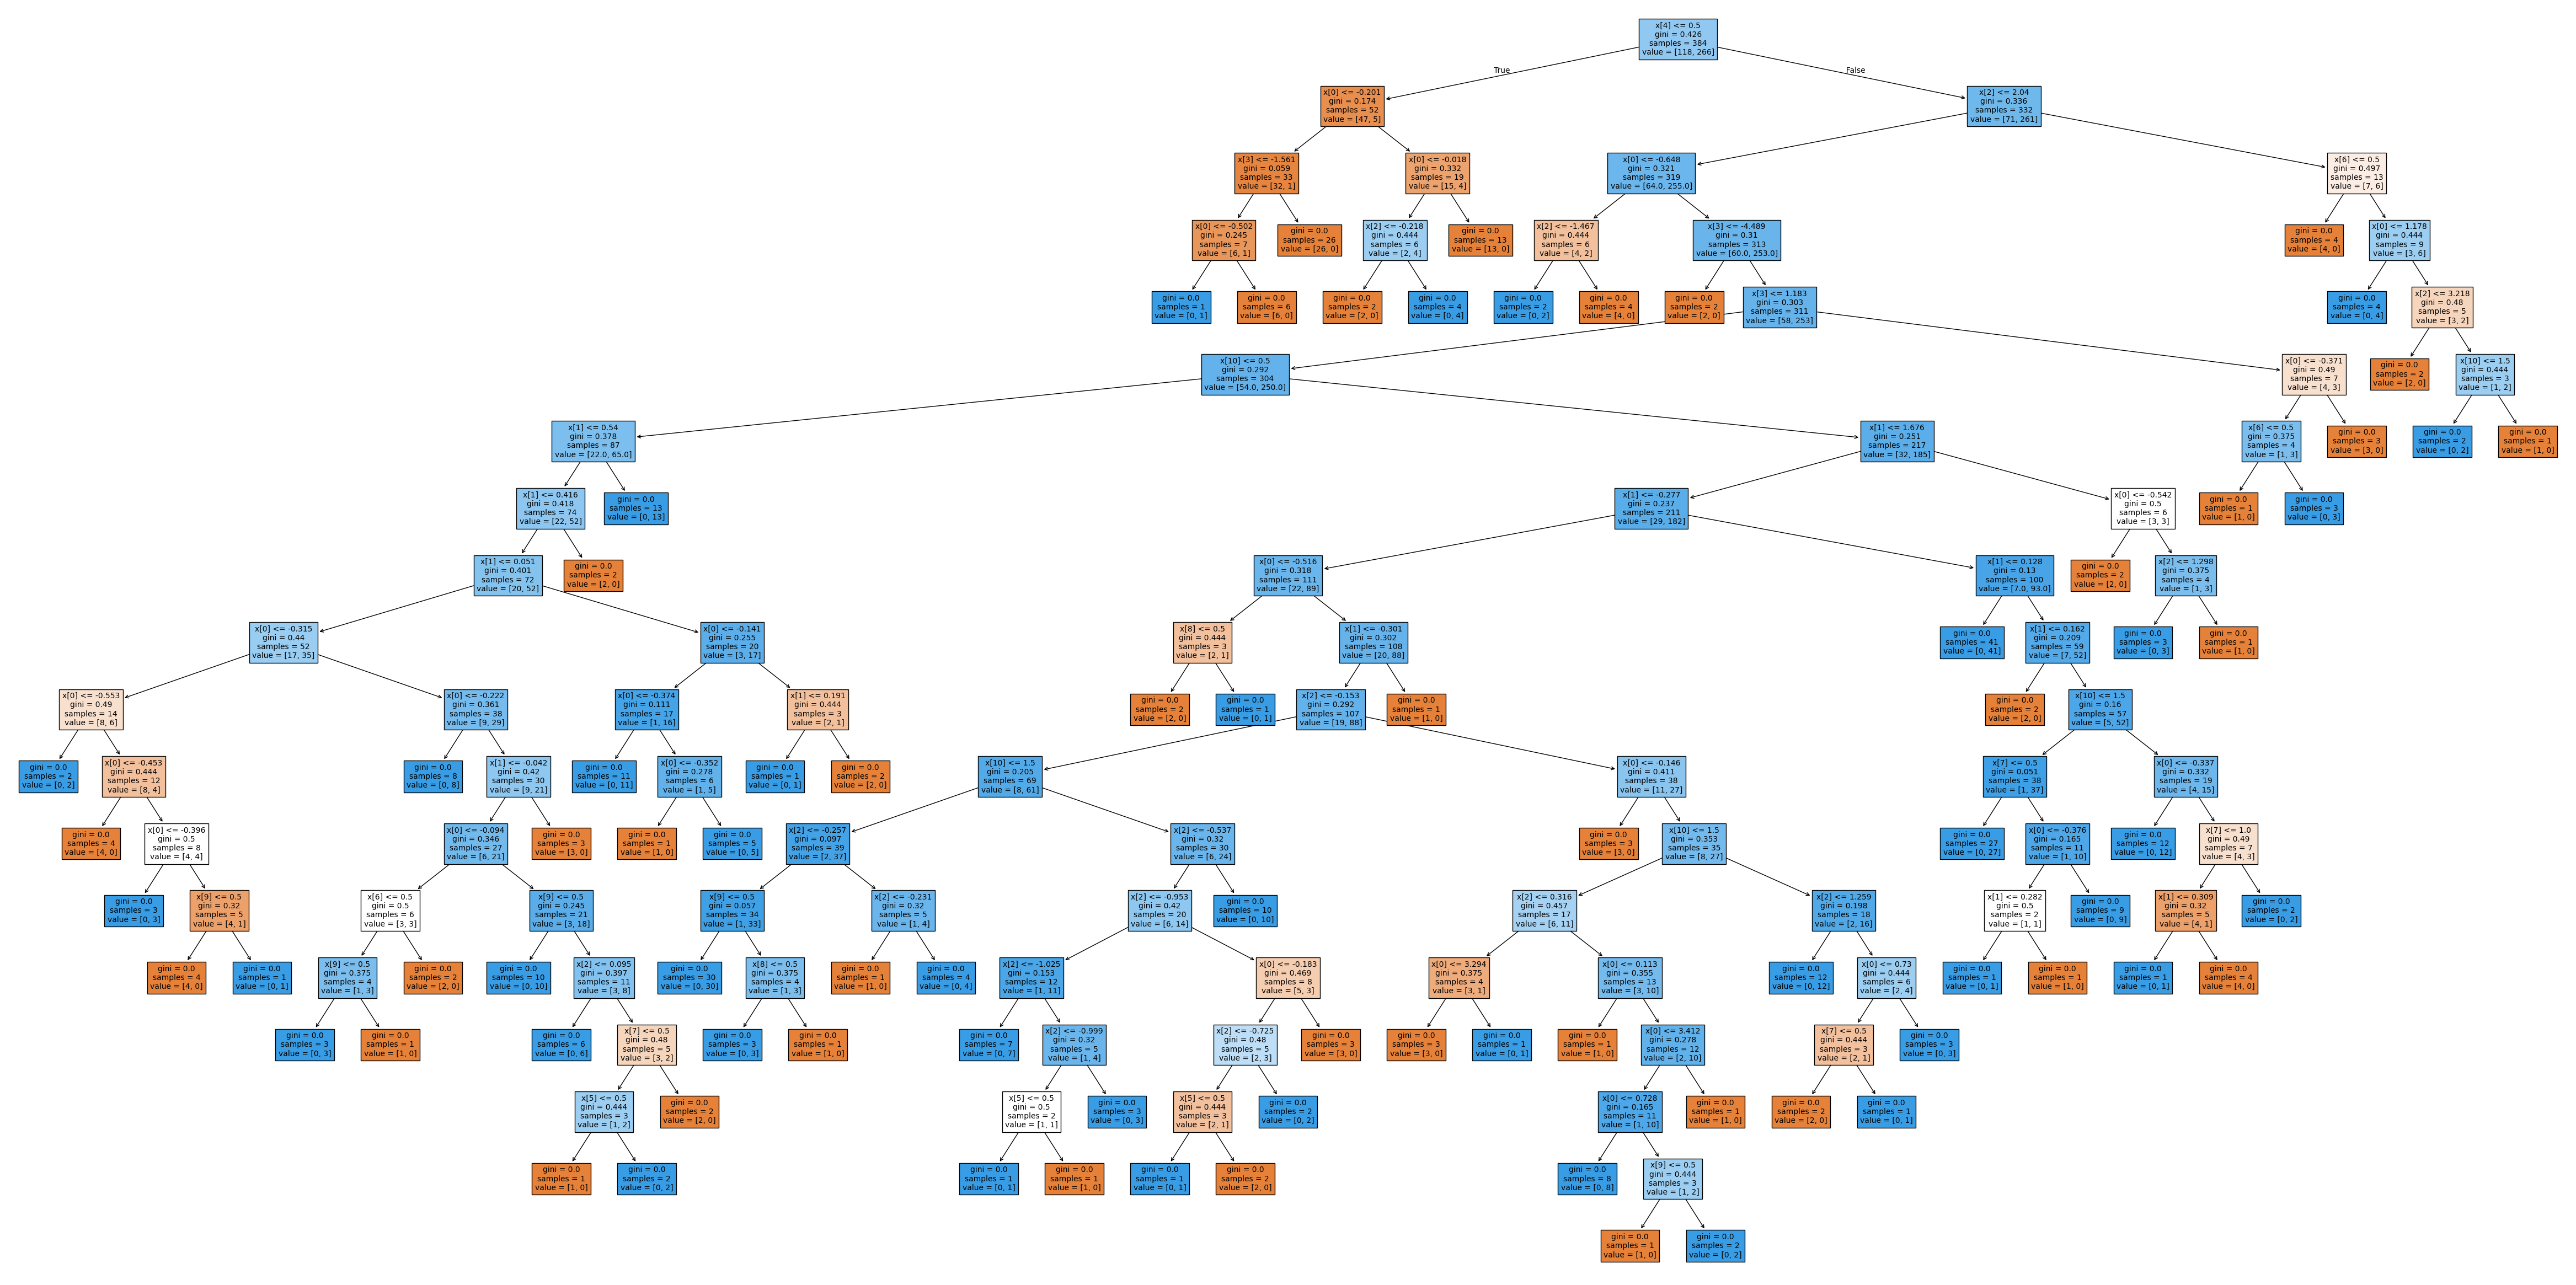

In [ ]:
plt.figure(figsize = (60,30))
plot_tree(dt, fontsize = 10, filled = True)
plt.savefig("DecisionTree.pdf")

16. Train Random Forest



In [ ]:
rfc = RandomForestClassifier(n_estimators=100,random_state=42)
rfc.fit(x_train,y_train)

RandomForestClassifier(random_state=42)

In [ ]:
rfc_predict = rfc.predict(x_test)
result = pd.DataFrame(
    {
        "Actual" : y_test,
        "Prediction_by_model" : rfc_predict
    }
)
result.head()

,Actual,Prediction_by_model
244,Y,Y
580,Y,Y
603,Y,Y
58,Y,Y
538,N,Y


17. Evaluate Random Forest



In [ ]:
ac_rfc = accuracy_score(y_test,y_predict)
prec_rfc = precision_score(y_test, y_predict, pos_label="Y")
rec_rfc = recall_score(y_test,y_predict,pos_label="Y")
f1_rfc = f1_score(y_test,y_predict,pos_label="Y")
print("Accuracy:", ac_rfc)
print("Precision:",prec_rfc)
print("Recall:",rec_rfc )
print("F1 score:", f1_rfc)
print("Confusion Matrix:\n", confusion_matrix(y_test,y_predict))

Accuracy: 0.7708333333333334
Precision: 0.84375
Recall: 0.8181818181818182
F1 score: 0.8307692307692308
Confusion Matrix:
 [[20 10]
 [12 54]]


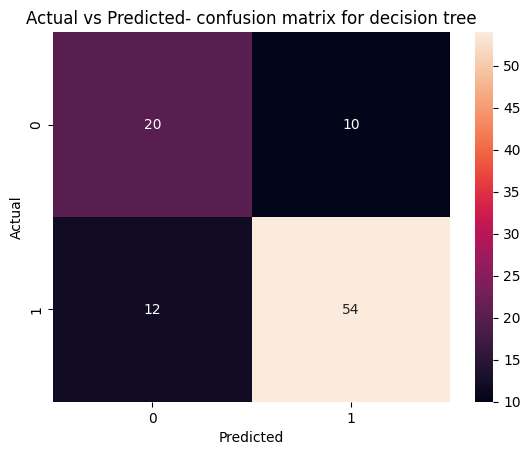

In [ ]:
import matplotlib.pyplot as plt
cm = confusion_matrix(y_test, y_predict)
sns.heatmap(cm, annot=True)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Actual vs Predicted- confusion matrix for decision tree")
plt.show()

18. Compare all three models


,model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.770833,0.84375,0.818182,0.830769
1,Decision Tree,0.770833,0.84375,0.818182,0.830769
2,Random Forest,0.770833,0.84375,0.818182,0.830769


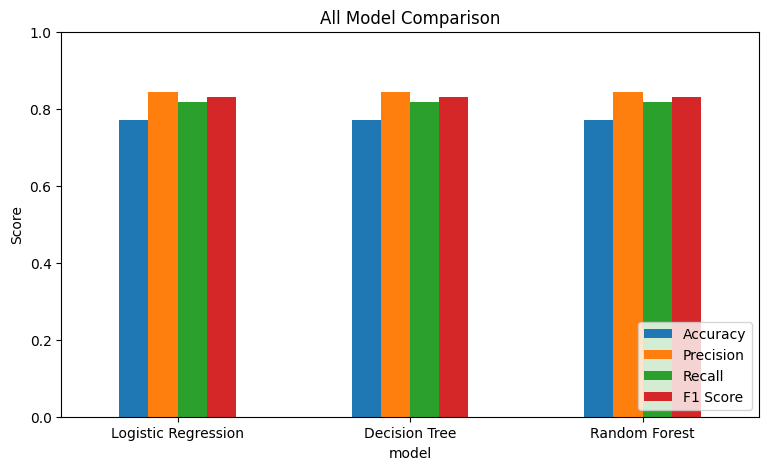

In [ ]:
comparison = pd.DataFrame({ "model": ["Logistic Regression", "Decision Tree", "Random Forest"],
                           "Accuracy": [ac_logr,ac_dt,ac_rfc],
                            "Precision": [prec_logr, prec_dt,prec_rfc],
                            "Recall": [rec_logr, rec_dt, rec_rfc],
                            "F1 Score": [f1_logr, f1_dt, f1_rfc]
})
display(comparison)

comparison.set_index("model").plot(kind="bar", figsize=(9, 5), ylim=(0, 1), rot=0)
plt.ylabel("Score")
plt.title("All Model Comparison")
plt.legend(loc="lower right")
plt.show()